# Machine Learning — Mining Process Quality Prediction

## 1. Project Overview

This notebook develops and evaluates machine learning regression models to predict iron concentrate and silica concentrate quality in an iron ore flotation process.

The objective is to investigate whether historical operational measurements can provide useful predictions of concentrate quality and to evaluate model performance on unseen data.

## 2. Dataset Information

- **Source:** Kaggle — Quality Prediction in a Mining Process : https://www.kaggle.com/code/korrapatyairit/ml-regression-quality-prediction-in-a-mining-proc/input
- **Cleaned records:** 736,282 rows
- **Columns:** 24
- **Time period:** March–September 2017
- **Input features:** 21 operational and process variables
- **Target variables:** `% Iron Concentrate` and `% Silica Concentrate`

## 3. Machine Learning Objectives

1. Prepare input features and target variables for regression.
2. Split the dataset chronologically into training and testing sets.
3. Train Random Forest Regression models for both target variables.
4. Evaluate predictions using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).
5. Compare Random Forest performance against a baseline model that predicts the training-set mean.
6. Examine potential differences between training and testing data distributions.
7. Identify limitations and opportunities for improving prediction performance.

## 4. Modeling Approach

Random Forest Regression is used to model potentially nonlinear relationships between operational process variables and concentrate quality.

The data is divided chronologically, with the first 80% used for training and the final 20% used for testing. This approach preserves the time order of observations and evaluates the model on later records.

A baseline model is also evaluated to determine whether Random Forest provides an improvement over a simple mean-based prediction.

## 5. Model Evaluation Metrics

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted values. Lower values indicate smaller errors.
- **RMSE (Root Mean Squared Error):** Measures prediction error while penalizing larger errors more heavily. Lower values are preferable.
- **R² (Coefficient of Determination):** Measures predictive performance relative to predicting the test-set mean. Values closer to 1 generally indicate better performance; a negative value indicates performance worse than the test-set mean benchmark.

## 6. Expected Output

The notebook produces model evaluation results for both concentrate targets, compares Random Forest against the baseline, and examines the limitations of the current approach.

The findings will be used to assess whether the available operational variables provide useful predictive information and to guide further model improvement.

**Important:** Model performance must be interpreted using the actual evaluation results. Training a model does not guarantee accurate predictions, and feature importance or correlation does not independently establish causation.

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Hubungkan Ke google drive

In [ ]:

import pandas as pd
import numpy as np

file_path = (
    "/content/drive/MyDrive/"
    "Mining_Process_Quality_Prediction/"
    "data/processed/mining_process_clean.csv"
)

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()


Dataset shape: (736282, 24)

Columns:
['date', '% Iron Feed', '% Silica Feed', 'Starch Flow', 'Amina Flow', 'Ore Pulp Flow', 'Ore Pulp pH', 'Ore Pulp Density', 'Flotation Column 01 Air Flow', 'Flotation Column 02 Air Flow', 'Flotation Column 03 Air Flow', 'Flotation Column 04 Air Flow', 'Flotation Column 05 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Flotation Column 05 Level', 'Flotation Column 06 Level', 'Flotation Column 07 Level', '% Iron Concentrate', '% Silica Concentrate']


,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,...,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,...,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,...,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31
3,2017-03-10 01:00:00,55.2,16.98,3047.36,568.665,397.939,10.0689,1.74,249.917,254.487,...,251.147,452.441,458.165,442.865,446.210,471.411,437.690,427.669,66.91,1.31
4,2017-03-10 01:00:00,55.2,16.98,3033.69,558.167,400.254,10.0697,1.74,250.203,252.136,...,248.928,452.441,452.900,450.523,453.670,462.598,443.682,425.679,66.91,1.31


##Membaca Dataset yang sudah di bersihkan

##Menyiapkan Fitur target mechine learning

In [ ]:

# 1. Periksa tipe data dan missing values
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nData types:")
print(df.dtypes.value_counts())

# 2. Tampilkan kolom target
target_columns = [
    "% Iron Concentrate",
    "% Silica Concentrate"
]

print("\nTarget columns:")
print([col for col in target_columns if col in df.columns])


Dataset shape: (736282, 24)

Missing values:
0

Data types:
float64    23
object      1
Name: count, dtype: int64

Target columns:
['% Iron Concentrate', '% Silica Concentrate']


##Siapkan data Training dan testing

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Urutkan data berdasarkan waktu
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Target prediksi
targets = ["% Iron Concentrate", "% Silica Concentrate"]

# Hilangkan kolom yang tidak boleh menjadi fitur
exclude_columns = targets + ["date", "Date", "Date1"]

# Gunakan kolom numerik sebagai fitur
feature_columns = [
    col for col in df.select_dtypes(include="number").columns
    if col not in exclude_columns
]

X = df[feature_columns]
y = df[targets]

# Pembagian kronologis: 80% awal untuk training, 20% akhir untuk testing
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Jumlah fitur:", len(feature_columns))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nFitur yang digunakan:")
print(feature_columns)


Jumlah fitur: 21
Training rows: 589025
Testing rows: 147257

Fitur yang digunakan:
['% Iron Feed', '% Silica Feed', 'Starch Flow', 'Amina Flow', 'Ore Pulp Flow', 'Ore Pulp pH', 'Ore Pulp Density', 'Flotation Column 01 Air Flow', 'Flotation Column 02 Air Flow', 'Flotation Column 03 Air Flow', 'Flotation Column 04 Air Flow', 'Flotation Column 05 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Flotation Column 05 Level', 'Flotation Column 06 Level', 'Flotation Column 07 Level']


Periksa Fitur,lalu latih model

In [ ]:

# Pastikan target tidak masuk ke fitur
print("Target masuk fitur?")
print(set(targets).intersection(feature_columns))

# Cek data kosong
print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum().sum())


Target masuk fitur?
set()

Missing values in X_train: 0
Missing values in y_train: 0


##Training Machine Learning dengan Random Forest

In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

start = time.time()

model_iron = RandomForestRegressor(
    n_estimators=20,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model_iron.fit(X_train, y_train["% Iron Concentrate"])

pred_iron = model_iron.predict(X_test)

print("IRON CONCENTRATE MODEL")
print("MAE:", round(mean_absolute_error(y_test["% Iron Concentrate"], pred_iron), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test["% Iron Concentrate"], pred_iron)), 4))
print("R²:", round(r2_score(y_test["% Iron Concentrate"], pred_iron), 4))
print("Training + prediction time:", round(time.time() - start, 2), "seconds")


IRON CONCENTRATE MODEL
MAE: 1.0064
RMSE: 1.3142
R²: -0.4085
Training + prediction time: 218.82 seconds


In [ ]:

start = time.time()

model_silica = RandomForestRegressor(
    n_estimators=20,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model_silica.fit(X_train, y_train["% Silica Concentrate"])

pred_silica = model_silica.predict(X_test)

print("SILICA CONCENTRATE MODEL")
print("MAE:", round(mean_absolute_error(
    y_test["% Silica Concentrate"], pred_silica), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(
    y_test["% Silica Concentrate"], pred_silica)), 4))
print("R²:", round(r2_score(
    y_test["% Silica Concentrate"], pred_silica), 4))
print("Training + prediction time:",
      round(time.time() - start, 2), "seconds")


SILICA CONCENTRATE MODEL
MAE: 0.9488
RMSE: 1.2033
R²: -0.1025
Training + prediction time: 217.73 seconds


##Tabel Evaluasi kedua Model

In [ ]:

import os
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

output_dir = "/content/drive/MyDrive/Mining_Process_Quality_Prediction/models"
os.makedirs(output_dir, exist_ok=True)

# Evaluasi baseline dan Random Forest
evaluation_results = []

for target, model, prediction in [
    ("% Iron Concentrate", model_iron, pred_iron),
    ("% Silica Concentrate", model_silica, pred_silica)
]:
    y_true = y_test[target].to_numpy()
    baseline_pred = np.full(len(y_true), y_train[target].mean())

    for model_name, pred in [
        ("Baseline", baseline_pred),
        ("Random Forest", prediction)
    ]:
        evaluation_results.append({
            "Target": target,
            "Model": model_name,
            "MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "R2": r2_score(y_true, pred)
        })

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df.round(4))

evaluation_df.to_csv(
    os.path.join(output_dir, "model_evaluation.csv"),
    index=False
)

print("Hasil evaluasi berhasil disimpan.")


,Target,Model,MAE,RMSE,R2
0,% Iron Concentrate,Baseline,0.8910,1.1685,-0.1134
1,% Iron Concentrate,Random Forest,1.0064,1.3142,-0.4085
2,% Silica Concentrate,Baseline,0.9474,1.1467,-0.0013
3,% Silica Concentrate,Random Forest,0.9488,1.2033,-0.1025


Hasil evaluasi berhasil disimpan.


In [ ]:

import os

output_dir = "/content/drive/MyDrive/Mining_Process_Quality_Prediction/models"
os.makedirs(output_dir, exist_ok=True)

evaluation_df.to_csv(
    os.path.join(output_dir, "model_evaluation.csv"),
    index=False
)

print("Tabel evaluasi berhasil disimpan!")


Tabel evaluasi berhasil disimpan!


##Hitung Feature Importance

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Feature importance untuk Iron Concentrate
iron_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_iron.feature_importances_
}).sort_values("Importance", ascending=False)

# Feature importance untuk Silica Concentrate
silica_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_silica.feature_importances_
}).sort_values("Importance", ascending=False)

print("TOP 10 FEATURES - IRON CONCENTRATE")
display(iron_importance.head(10).round(4))

print("TOP 10 FEATURES - SILICA CONCENTRATE")
display(silica_importance.head(10).round(4))


TOP 10 FEATURES - IRON CONCENTRATE


,Feature,Importance
0,% Iron Feed,0.1530
1,% Silica Feed,0.1460
10,Flotation Column 04 Air Flow,0.0906
16,Flotation Column 03 Level,0.0818
5,Ore Pulp pH,0.0789
18,Flotation Column 05 Level,0.0762
3,Amina Flow,0.0554
9,Flotation Column 03 Air Flow,0.0529
11,Flotation Column 05 Air Flow,0.0495
15,Flotation Column 02 Level,0.0406


TOP 10 FEATURES - SILICA CONCENTRATE


,Feature,Importance
1,% Silica Feed,0.1396
9,Flotation Column 03 Air Flow,0.1366
10,Flotation Column 04 Air Flow,0.1244
0,% Iron Feed,0.1162
3,Amina Flow,0.1057
5,Ore Pulp pH,0.0518
11,Flotation Column 05 Air Flow,0.0462
16,Flotation Column 03 Level,0.0423
14,Flotation Column 01 Level,0.0409
15,Flotation Column 02 Level,0.0374


In [ ]:

import os

output_dir = "/content/drive/MyDrive/Mining_Process_Quality_Prediction/models"
os.makedirs(output_dir, exist_ok=True)

iron_importance.to_csv(
    os.path.join(output_dir, "iron_feature_importance.csv"),
    index=False
)

silica_importance.to_csv(
    os.path.join(output_dir, "silica_feature_importance.csv"),
    index=False
)

print("Kedua hasil Feature Importance berhasil disimpan.")


Kedua hasil Feature Importance berhasil disimpan.


##Buat Grafik

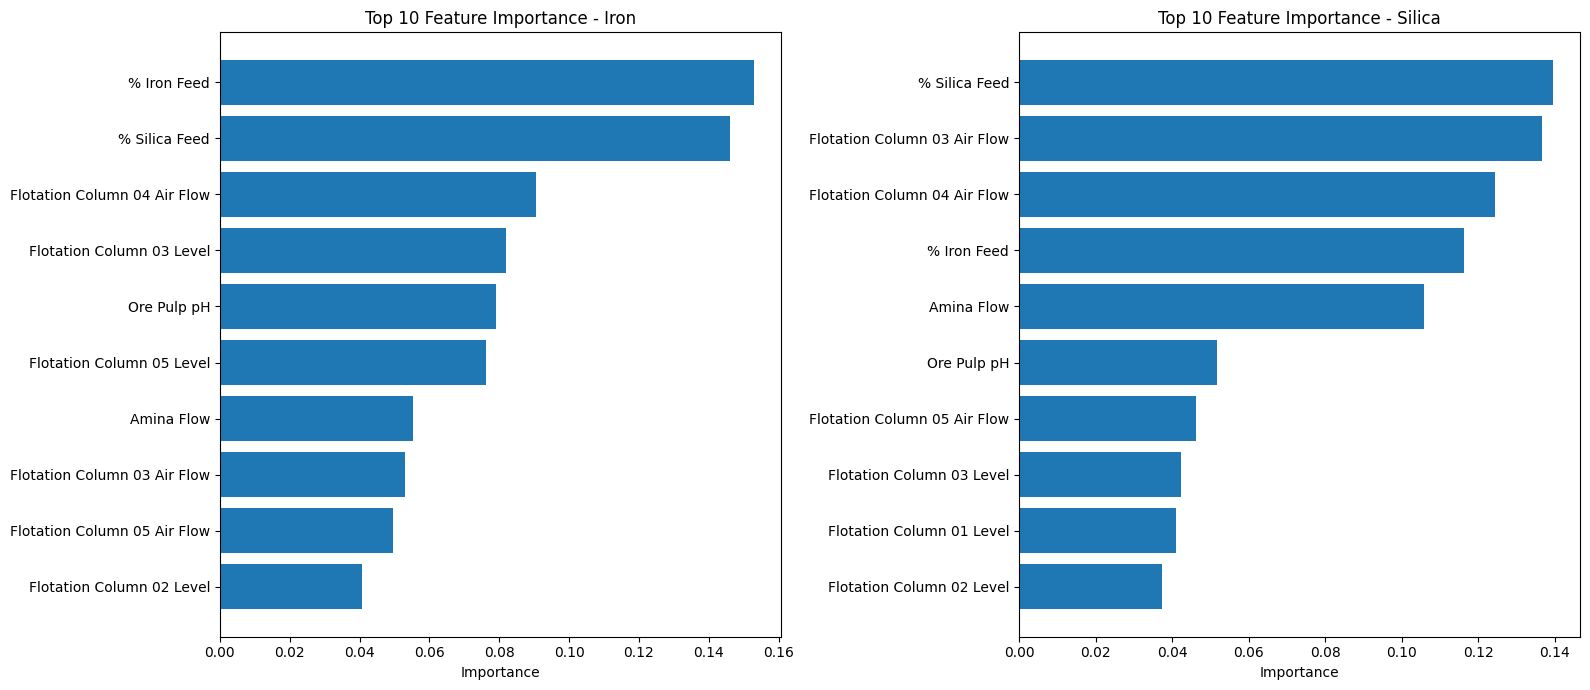

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

iron_top10 = iron_importance.head(10).sort_values("Importance")
silica_top10 = silica_importance.head(10).sort_values("Importance")

axes[0].barh(iron_top10["Feature"], iron_top10["Importance"])
axes[0].set_title("Top 10 Feature Importance - Iron")
axes[0].set_xlabel("Importance")

axes[1].barh(silica_top10["Feature"], silica_top10["Importance"])
axes[1].set_title("Top 10 Feature Importance - Silica")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()


Feature importance menunjukkan seberapa banyak fitur digunakan untuk membantu prediksi model, bukan membuktikan hubungan sebab-akibat. Karena nilai R² kedua model masih negatif, interpretasinya perlu hati-hati.

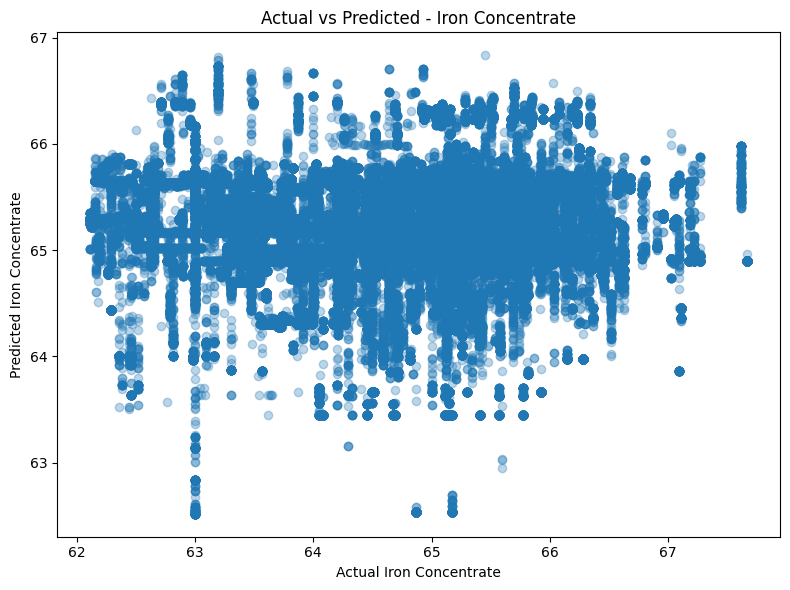

In [35]:

import matplotlib.pyplot as plt
import os

# Folder untuk menyimpan gambar
output_dir = "/content/drive/MyDrive/Mining_Process_Quality_Prediction/images"
os.makedirs(output_dir, exist_ok=True)

# Grafik Actual vs Predicted untuk Iron Concentrate
plt.figure(figsize=(8, 6))
plt.scatter(y_test["% Iron Concentrate"], pred_iron, alpha=0.3)
plt.xlabel("Actual Iron Concentrate")
plt.ylabel("Predicted Iron Concentrate")
plt.title("Actual vs Predicted - Iron Concentrate")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "actual_vs_predicted.png"), dpi=300)
plt.show()


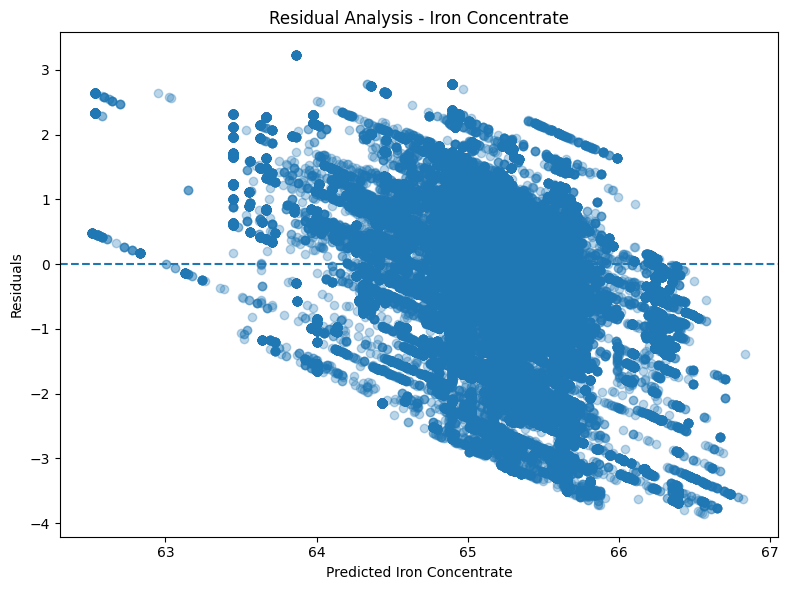

In [36]:

# Residual Analysis untuk Iron Concentrate
residuals = y_test["% Iron Concentrate"] - pred_iron

plt.figure(figsize=(8, 6))
plt.scatter(pred_iron, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Iron Concentrate")
plt.ylabel("Residuals")
plt.title("Residual Analysis - Iron Concentrate")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "residual_plot.png"), dpi=300)
plt.show()


##Simpan kedua model ke Google Drive

In [ ]:

import os
import joblib
from google.colab import drive

# Hubungkan Google Drive jika belum terhubung
drive.mount('/content/drive')

# Folder output project
output_dir = "/content/drive/MyDrive/Mining_Process_Quality_Prediction/models"
os.makedirs(output_dir, exist_ok=True)

# Simpan model yang sudah dilatih
joblib.dump(model_iron, os.path.join(output_dir, "iron_concentrate_model.pkl"))
joblib.dump(model_silica, os.path.join(output_dir, "silica_concentrate_model.pkl"))

print("Kedua model berhasil disimpan.")
print("Lokasi:", output_dir)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kedua model berhasil disimpan.
Lokasi: /content/drive/MyDrive/Mining_Process_Quality_Prediction/models


## 7. Model Results and Interpretation

### 7.1 Model Performance

Random Forest Regression was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). A mean-based baseline was also used for comparison.

The initial evaluation results showed negative R² values for both iron concentrate and silica concentrate. The Random Forest models did not outperform the baseline on the evaluated test data.

These findings indicate that the current models have limited predictive performance and require further investigation before they can be considered suitable for operational prediction.

### 7.2 Feature Importance

For the iron concentrate model, `% Iron Feed` and `% Silica Feed` were the two highest-ranked features in the current Random Forest model.

For the silica concentrate model, `% Silica Feed`, `Flotation Column 03 Air Flow`, and `Flotation Column 04 Air Flow` were among the highest-ranked features.

Feature importance describes how the trained model uses input variables to generate predictions. It does not establish that a variable directly causes changes in concentrate quality.

### 7.3 Limitations

The current analysis has several limitations:

1. The Random Forest models have not demonstrated better predictive performance than the baseline.
2. The dataset covers March to September 2017, so its findings may not generalize to other operating periods.
3. Operational measurements may have complex relationships, time dependencies, and measurement noise.
4. Feature importance alone does not establish causal relationships.
5. Further validation and model improvement are required before practical deployment.

### 7.4 Recommended Next Steps

- Investigate the baseline comparison and prediction errors.
- Compare alternative regression algorithms.
- Examine feature relationships and possible time-dependent effects.
- Evaluate improvements using the same chronological test period.
- Document the final model metrics and limitations transparently.

### 7.5 Conclusion

This project demonstrates an end-to-end analytical workflow involving data cleaning, exploratory data analysis, process quality visualization, and regression modeling.

Although the current Random Forest models have not yet outperformed the baseline, the evaluation provides a useful starting point for further experimentation. The results highlight the importance of validating model performance rather than assuming that a trained model is necessarily accurate.

##Training model alternatif

In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

alternative_results = []
alternative_models = {}
alternative_predictions = {}

for target in ["% Iron Concentrate", "% Silica Concentrate"]:
    start = time.time()

    model_alt = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )

    model_alt.fit(X_train, y_train[target])
    prediction = model_alt.predict(X_test)

    alternative_models[target] = model_alt
    alternative_predictions[target] = prediction

    alternative_results.append({
        "Target": target,
        "Model": "HistGradientBoosting",
        "MAE": mean_absolute_error(y_test[target], prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test[target], prediction)),
        "R2": r2_score(y_test[target], prediction),
        "Training_Prediction_Time_Seconds": round(time.time() - start, 2)
    })

alternative_df = pd.DataFrame(alternative_results)
display(alternative_df.round(4))


,Target,Model,MAE,RMSE,R2,Training_Prediction_Time_Seconds
0,% Iron Concentrate,HistGradientBoosting,0.8958,1.1860,-0.1472,23.13
1,% Silica Concentrate,HistGradientBoosting,0.8841,1.1103,0.0613,8.98


Gabungkan hasil Semua Model

In [ ]:

# Gabungkan hasil HistGradientBoosting dan Random Forest
# Pastikan evaluation_df berisi hasil Random Forest dan baseline.

comparison_df = pd.concat(
    [evaluation_df, alternative_df],
    ignore_index=True
)

display(
    comparison_df.sort_values(
        ["Target", "MAE"]
    ).round(4)
)


,Target,Model,MAE,RMSE,R2,Training_Prediction_Time_Seconds
0,% Iron Concentrate,Baseline,0.8910,1.1685,-0.1134,NaN
4,% Iron Concentrate,HistGradientBoosting,0.8958,1.1860,-0.1472,23.13
1,% Iron Concentrate,Random Forest,1.0064,1.3142,-0.4085,NaN
5,% Silica Concentrate,HistGradientBoosting,0.8841,1.1103,0.0613,8.98
2,% Silica Concentrate,Baseline,0.9474,1.1467,-0.0013,NaN
3,% Silica Concentrate,Random Forest,0.9488,1.2033,-0.1025,NaN


Interpretasinya:
- Iron Concentrate: Baseline masih lebih baik daripada kedua model ML berdasarkan MAE. HistGradientBoosting memiliki RMSE lebih rendah daripada baseline, tetapi R² lebih buruk.
- Silica Concentrate: HistGradientBoosting memberikan MAE dan RMSE terendah serta R² positif. Namun, R² sebesar 0.0613 masih menunjukkan kemampuan prediksi yang lemah.
- Random Forest: Belum mengalahkan baseline untuk kedua target.

Simpan tabel perbandingan

In [ ]:

comparison_path = (
    "/content/drive/MyDrive/"
    "Mining_Process_Quality_Prediction/models/"
    "model_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("Tabel perbandingan berhasil disimpan:")
print(comparison_path)


Tabel perbandingan berhasil disimpan:
/content/drive/MyDrive/Mining_Process_Quality_Prediction/models/model_comparison.csv


Simpan model HistGradientBoosting

In [ ]:

import os
import joblib

# Folder penyimpanan model
model_dir = (
    "/content/drive/MyDrive/"
    "Mining_Process_Quality_Prediction/models"
)
os.makedirs(model_dir, exist_ok=True)

# Simpan model untuk Iron Concentrate
joblib.dump(
    alternative_models["% Iron Concentrate"],
    os.path.join(model_dir, "hist_gradient_boosting_iron.joblib")
)

# Simpan model untuk Silica Concentrate
joblib.dump(
    alternative_models["% Silica Concentrate"],
    os.path.join(model_dir, "hist_gradient_boosting_silica.joblib")
)

print("Kedua model HistGradientBoosting berhasil disimpan!")
print("Folder:", model_dir)


Kedua model HistGradientBoosting berhasil disimpan!
Folder: /content/drive/MyDrive/Mining_Process_Quality_Prediction/models


In [ ]:

print("File model yang tersimpan:")

for filename in os.listdir(model_dir):
    print(filename)


File model yang tersimpan:
iron_concentrate_model.pkl
silica_concentrate_model.pkl
model_evaluation.csv
iron_feature_importance.csv
silica_feature_importance.csv
model_comparison.csv
hist_gradient_boosting_iron.joblib
hist_gradient_boosting_silica.joblib


Verifikasi file model

In [ ]:

import os

print("VERIFIKASI FILE MODEL")

for filename in [
    "iron_concentrate_model.pkl",
    "silica_concentrate_model.pkl",
    "hist_gradient_boosting_iron.joblib",
    "hist_gradient_boosting_silica.joblib",
    "model_evaluation.csv",
    "model_comparison.csv",
]:
    path = os.path.join(model_dir, filename)
    print(f"{filename}: {'ADA' if os.path.exists(path) else 'TIDAK DITEMUKAN'}")


VERIFIKASI FILE MODEL
iron_concentrate_model.pkl: ADA
silica_concentrate_model.pkl: ADA
hist_gradient_boosting_iron.joblib: ADA
hist_gradient_boosting_silica.joblib: ADA
model_evaluation.csv: ADA
model_comparison.csv: ADA


## 8. Model Evaluation and Interpretation

### Model Comparison

Three approaches were evaluated for predicting iron concentrate and silica concentrate: a baseline model, Random Forest, and HistGradientBoosting.

The baseline model provides a reference point for evaluating whether machine learning improves prediction performance. Model performance is assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

### Key Findings

- **Iron Concentrate:** The HistGradientBoosting model achieved an MAE of approximately 0.8958 and an RMSE of 1.1860, with an R² of -0.1472.
- **Silica Concentrate:** The HistGradientBoosting model achieved an MAE of approximately 0.8841 and an RMSE of 1.1103, with an R² of 0.0613.
- **Model comparison:** HistGradientBoosting improved the MAE and RMSE for both targets compared with the Random Forest results shown in the evaluation table. However, the baseline model remained competitive.

### Limitations

The negative R² for iron concentrate indicates that the model performed worse than predicting the mean of the test target. The silica model's R² of 0.0613 indicates that it explains only a small proportion of the variation in the test data.

Therefore, the current models have limited predictive performance and should not yet be used for operational decisions. Further work could explore feature engineering, time-aware validation, hyperparameter tuning, and additional process variables.

### Conclusion

This project demonstrates a complete initial machine learning workflow, including chronological train-test splitting, baseline evaluation, model comparison, feature importance analysis, and model persistence. The results also highlight why evaluation metrics must be examined critically rather than assuming that a trained model is automatically useful.

## 09. Final Project Summary

### Project Overview

This project analyzes the quality of an iron ore flotation process using historical operational data from March to September 2017. The objective is to investigate process characteristics and develop machine learning models to predict iron concentrate and silica concentrate levels.

### Project Workflow

1. **Data Cleaning:** Validated data quality, checked missing values and duplicate records, and prepared the cleaned dataset.
2. **Exploratory Data Analysis (EDA):** Investigated distributions, correlations, outliers, and changes in process measurements over time.
3. **SQL Analysis:** Prepared the dataset for structured queries and operational analysis.
4. **Machine Learning:** Developed baseline, Random Forest, and HistGradientBoosting regression models.
5. **Model Evaluation:** Compared models using MAE, RMSE, and R².
6. **Feature Importance:** Examined which input variables contributed most to the tree-based models' predictions.
7. **Model Persistence:** Saved trained model files and evaluation outputs to Google Drive.

### Main Findings

The current HistGradientBoosting models show lower MAE and RMSE than the evaluated Random Forest models for both targets. However, the iron concentrate model has a negative R², while the silica concentrate model has a low positive R². These results indicate that predictive performance remains limited and requires further improvement.

Feature importance results identify potentially informative process variables, but importance scores should not be interpreted as proof of causation.

### Business Relevance

The analysis provides an initial framework for exploring how flotation process measurements relate to concentrate quality. With further validation and model improvement, this workflow could support process monitoring, quality analysis, and future operational decision-support studies.

### Project Limitations and Future Work

- Improve predictive performance through feature engineering and hyperparameter tuning.
- Compare additional regression algorithms.
- Evaluate models using appropriate chronological validation.
- Investigate prediction errors across different operating periods.
- Integrate the analytical findings into an interactive Power BI dashboard.

### Final Conclusion

This project demonstrates an end-to-end data science workflow, from data preparation and exploration to SQL analysis, regression modeling, evaluation, and visualization. The current results provide a foundation for further research rather than a production-ready quality prediction system.